### Import Libraries

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

In [2]:
data = pd.read_csv("messidor_features.csv")

In [3]:
data.head()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,Class
0,1.0,1.0,22.0,22.0,22.0,19.0,18.0,14.0,49.895756,17.775994,5.270920,0.771761,0.018632,0.006864,0.003923,0.003923,0.486903,0.100025,1.0,0
1,1.0,1.0,24.0,24.0,22.0,18.0,16.0,13.0,57.709936,23.799994,3.325423,0.234185,0.003903,0.003903,0.003903,0.003903,0.520908,0.144414,0.0,0
2,1.0,1.0,62.0,60.0,59.0,54.0,47.0,33.0,55.831441,27.993933,12.687485,4.852282,1.393889,0.373252,0.041817,0.007744,0.530904,0.128548,0.0,1
3,1.0,1.0,55.0,53.0,53.0,50.0,43.0,31.0,40.467228,18.445954,9.118901,3.079428,0.840261,0.272434,0.007653,0.001531,0.483284,0.114790,0.0,0
4,1.0,1.0,44.0,44.0,44.0,41.0,39.0,27.0,18.026254,8.570709,0.410381,0.000000,0.000000,0.000000,0.000000,0.000000,0.475935,0.123572,0.0,1


In [4]:
data.shape

(1146, 20)

In [5]:
X = data.drop(columns=["Class"])
y = data["Class"]

In [6]:
X.shape

(1146, 19)

In [7]:
y.shape

(1146,)

### Split dataset into train and test data

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,
                                                    random_state=42, stratify=y)

In [9]:
X_train.shape

(916, 19)

In [10]:
X_test.shape

(230, 19)

In [11]:
y_train.value_counts().sort_index()

,count
Class,
0,432
1,484


In [12]:
y_test.value_counts().sort_index()

,count
Class,
0,108
1,122


### Feature Scaling

In [13]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

In [14]:
scaler = StandardScaler()

In [15]:
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [16]:
results = []

### Logistic Regression

In [17]:
from sklearn.linear_model import LogisticRegression

In [18]:
logit_model = LogisticRegression(max_iter=1000, random_state=42)

In [19]:
logit_model.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000, random_state=42)

In [20]:
y_pred_logit = logit_model.predict(X_test_scaled)

In [21]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef, roc_auc_score

In [22]:
y_prob_logit = logit_model.predict_proba(X_test_scaled)[:, 1]

In [23]:
results.append({
    "Model": "Logistic Regression",
    "Accuracy": accuracy_score(y_test, y_pred_logit),
    "AUC": roc_auc_score(y_test, y_prob_logit),
    "Precision": precision_score(y_test, y_pred_logit, zero_division=0),
    "Recall": recall_score(y_test, y_pred_logit, zero_division=0),
    "F1 Score": f1_score(y_test, y_pred_logit, zero_division=0),
    "MCC": matthews_corrcoef(y_test, y_pred_logit)
})

In [24]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

In [25]:
confusion_matrix_logit = confusion_matrix(y_test, y_pred_logit)

In [26]:
display_cf = ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix_logit,
    display_labels=logit_model.classes_
)

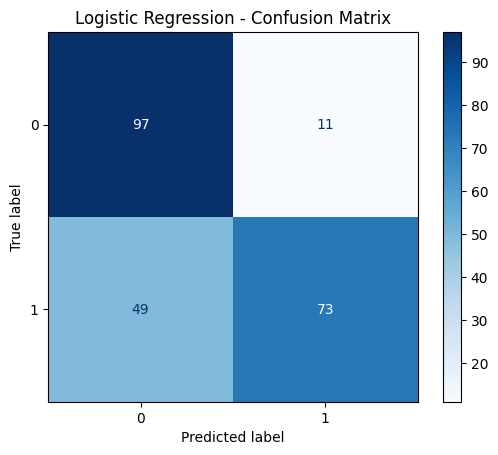

In [27]:
display_cf.plot(cmap="Blues")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

### Decision Tree

In [28]:
from sklearn.tree import DecisionTreeClassifier

In [29]:
dt_model = DecisionTreeClassifier(random_state=42)

In [30]:
dt_model.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

In [31]:
y_pred_dt = dt_model.predict(X_test)

In [32]:
y_prob_dt = dt_model.predict_proba(X_test)[:, 1]

In [33]:
results.append({
    "Model": "Decision Tree",
    "Accuracy": accuracy_score(y_test, y_pred_dt),
    "AUC": roc_auc_score(y_test, y_prob_dt),
    "Precision": precision_score(y_test, y_pred_dt, zero_division=0),
    "Recall": recall_score(y_test, y_pred_dt, zero_division=0),
    "F1 Score": f1_score(y_test, y_pred_dt, zero_division=0),
    "MCC": matthews_corrcoef(y_test, y_pred_dt)
})

In [34]:
confusion_matrix_dt = confusion_matrix(y_test, y_pred_dt)

In [35]:
display_cf_dt = ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix_dt,
    display_labels=dt_model.classes_
)

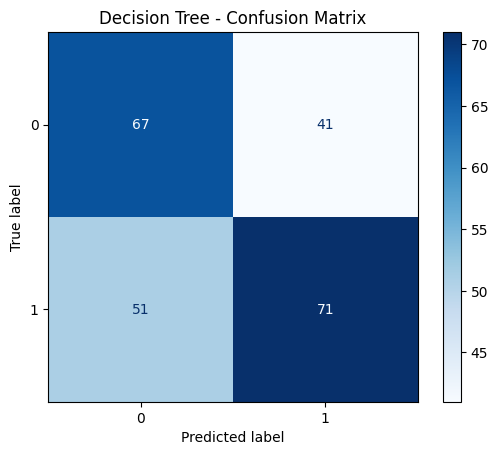

In [36]:
display_cf_dt.plot(cmap="Blues")
plt.title("Decision Tree - Confusion Matrix")
plt.show()

In [37]:
from sklearn.neighbors import KNeighborsClassifier

In [38]:
knn_model = KNeighborsClassifier(n_neighbors=5)

In [39]:
knn_model.fit(X_train_scaled, y_train)

KNeighborsClassifier()

In [40]:
y_pred_knn = knn_model.predict(X_test_scaled)

In [41]:
y_prob_knn = knn_model.predict_proba(X_test_scaled)[:, 1]

In [42]:
results.append({
    "Model": "KNN",
    "Accuracy": accuracy_score(y_test, y_pred_knn),
    "AUC": roc_auc_score(y_test, y_prob_knn),
    "Precision": precision_score(y_test, y_pred_knn, zero_division=0),
    "Recall": recall_score(y_test, y_pred_knn, zero_division=0),
    "F1 Score": f1_score(y_test, y_pred_knn, zero_division=0),
    "MCC": matthews_corrcoef(y_test, y_pred_knn)
})

In [43]:
confusion_matrix_knn = confusion_matrix(y_test, y_pred_knn)

In [44]:
display_cf_knn = ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix_knn,
    display_labels=knn_model.classes_
)

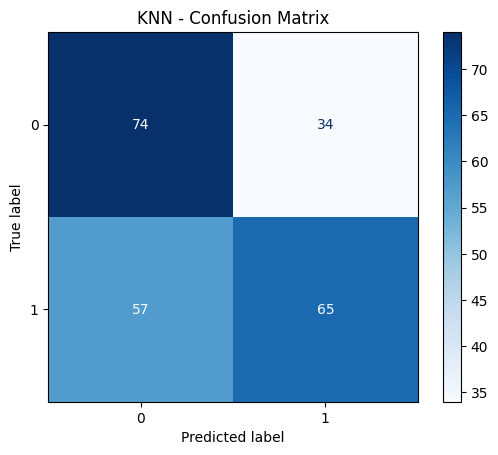

In [45]:
display_cf_knn.plot(cmap="Blues")
plt.title("KNN - Confusion Matrix")
plt.show()

In [46]:
from sklearn.naive_bayes import GaussianNB

In [47]:
nb_model = GaussianNB()

In [48]:
nb_model.fit(X_train, y_train)

GaussianNB()

In [49]:
y_pred_nb = nb_model.predict(X_test)

In [50]:
y_prob_nb = nb_model.predict_proba(X_test)[:, 1]

In [51]:
results.append({
    "Model": "Gaussian Naive Bayes",
    "Accuracy": accuracy_score(y_test, y_pred_nb),
    "AUC": roc_auc_score(y_test, y_prob_nb),
    "Precision": precision_score(y_test, y_pred_nb, zero_division=0),
    "Recall": recall_score(y_test, y_pred_nb, zero_division=0),
    "F1 Score": f1_score(y_test, y_pred_nb, zero_division=0),
    "MCC": matthews_corrcoef(y_test, y_pred_nb)
})

In [52]:
confusion_matrix_nb = confusion_matrix(y_test, y_pred_nb)

In [53]:
display_cf_nb = ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix_nb,
    display_labels=nb_model.classes_
)

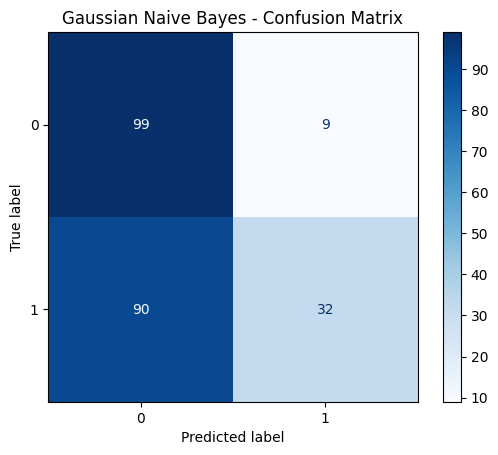

In [54]:
display_cf_nb.plot(cmap="Blues")
plt.title("Gaussian Naive Bayes - Confusion Matrix")
plt.show()

In [55]:
from sklearn.svm import SVC

In [56]:
svm_model = SVC(kernel="rbf", random_state=42)

In [57]:
svm_model.fit(X_train_scaled, y_train)

SVC(random_state=42)

In [58]:
y_pred_svm = svm_model.predict(X_test_scaled)

In [59]:
y_score_svm = svm_model.decision_function(X_test_scaled)

In [60]:
results.append({
    "Model": "SVM",
    "Accuracy": accuracy_score(y_test, y_pred_svm),
    "AUC": roc_auc_score(y_test, y_score_svm),
    "Precision": precision_score(y_test, y_pred_svm, zero_division=0),
    "Recall": recall_score(y_test, y_pred_svm, zero_division=0),
    "F1 Score": f1_score(y_test, y_pred_svm, zero_division=0),
    "MCC": matthews_corrcoef(y_test, y_pred_svm)
})

In [61]:
confusion_matrix_svm = confusion_matrix(y_test, y_pred_svm)

In [62]:
display_cf_svm = ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix_svm,
    display_labels=svm_model.classes_
)

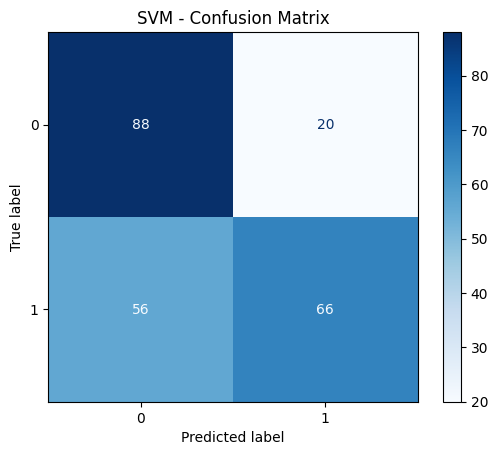

In [63]:
display_cf_svm.plot(cmap="Blues")
plt.title("SVM - Confusion Matrix")
plt.show()

In [64]:
results_df = pd.DataFrame(results)

In [65]:
results_df.head()

,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.739130,0.815270,0.869048,0.598361,0.708738,0.514639
1,Decision Tree,0.600000,0.601169,0.633929,0.581967,0.606838,0.202031
2,KNN,0.604348,0.652588,0.656566,0.532787,0.588235,0.219705
3,Gaussian Naive Bayes,0.569565,0.698619,0.780488,0.262295,0.392638,0.233361
4,SVM,0.669565,0.780662,0.767442,0.540984,0.634615,0.366999
